# TD 1 — Rappel de packages Python pour l’analyse de systèmes énergétiques

Ce notebook reprend trois tutoriels du cours de [Fabian Neumann de TU Berlin](https://fneum.github.io/data-science-for-esm/) sur des packages utilisés en modélisation de systèmes énergétiques.

Ordre des parties : pandas, GeoPandas/Cartopy, puis Rasterio/atlite.

**À noter :** le notebook source pandas ne contient pas l’URL directe du CSV de facteurs de charge irlandais. La cellule de correction correspondante laisse donc un emplacement à renseigner depuis [model.energy](https://model.energy), plutôt que d’inventer une URL.

# Pandas

<img src="https://pandas.pydata.org/static/img/pandas.svg" width="300px" />

[Pandas](http://pandas.pydata.org/) est une bibliothèque qui fournit des tableaux de type « Excel » en Python.
Elle permet de lire, écrire et traiter efficacement des données : tri, filtrage, agrégation, visualisation. Elle offre aussi des outils pour gérer les données manquantes et les séries temporelles.

<img src="https://media.geeksforgeeks.org/wp-content/cdn-uploads/creating_dataframe1.png" width="720px" />

In [1]:
# Convention : on importe pandas sous l'alias pd et numpy sous l'alias np
import pandas as pd
import numpy as np

## La `Series`

Une `Series` représente un tableau de données à une dimension. La différence principale avec un tableau `numpy` est qu'une `Series` possède un **index** : les étiquettes qui servent à accéder aux données. Elle ressemble beaucoup à un dictionnaire Python, où chaque valeur est associée à une clé.

Il existe de nombreuses façons de [créer une Series](https://pandas.pydata.org/pandas-docs/stable/dsintro.html#series), mais le constructeur de base est [`pd.Series()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.html), qui sait transformer un dictionnaire en `Series`.



In [2]:
# Un dictionnaire Python : clé = nom de la centrale, valeur = puissance installée (MW)
dictionary = {
    "Neckarwestheim": 1269,
    "Isar 2": 1365,
    "Emsland": 1290,
}

# pd.Series transforme le dictionnaire : les clés deviennent l'index, les valeurs les données
s = pd.Series(dictionary)
s

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
dtype: int64

In [3]:
# Pour comparer : le dictionnaire d'origine (pas d'opérations vectorielles possibles dessus)
dictionary

{'Neckarwestheim': 1269, 'Isar 2': 1365, 'Emsland': 1290}

Les opérations arithmétiques et la plupart des fonctions `numpy` s'appliquent aux `pd.Series`.
Point important : la `Series` conserve son index pendant ces opérations.

In [4]:
# Les opérations s'appliquent à toutes les valeurs d'un coup, et l'index est conservé
np.log(s) / s**0.5

Neckarwestheim    0.200600
Isar 2            0.195391
Emsland           0.199418
dtype: float64

On peut accéder à l'objet index sous-jacent si nécessaire :

In [5]:
# L'index : la liste des étiquettes des lignes
s.index

Index(['Neckarwestheim', 'Isar 2', 'Emsland'], dtype='str')

On récupère des valeurs à partir de leur étiquette d'index avec l'attribut `.loc` :

In [6]:
# Accès par ÉTIQUETTE avec .loc
s.loc["Isar 2"]

np.int64(1365)

Ou à partir de leur position avec `.iloc` (le premier élément a la position 0) :

In [7]:
# Accès par POSITION avec .iloc (la première ligne a la position 0, la troisième la position 2)
s.iloc[2]

np.int64(1290)

On peut passer une liste ou un tableau à `.loc` pour récupérer plusieurs lignes :

In [8]:
# Plusieurs lignes à la fois : on passe une liste d'étiquettes (double crochet)
s.loc[["Neckarwestheim", "Emsland"]]

Neckarwestheim    1269
Emsland           1290
dtype: int64

On peut utiliser la notation de *tranche* (`:`) pour obtenir une plage de lignes. Avec `.loc`, la borne de fin est **incluse** ; avec `.iloc`, elle est **exclue** :

In [9]:
# Tranche par étiquettes : les deux bornes sont INCLUSES avec .loc
s.loc["Neckarwestheim":"Emsland"]

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
dtype: int64

In [10]:
# Tranche par positions : la borne de fin est EXCLUE avec .iloc (ici les positions 0 et 1)
s.iloc[:2]

Neckarwestheim    1269
Isar 2            1365
dtype: int64

Si besoin, on peut toujours récupérer les données brutes :

In [11]:
# .values renvoie les données brutes, sans l'index
type(s.values)  # un tableau numpy

numpy.ndarray

## Le `DataFrame`

Une `pandas.Series` n'a qu'une seule **colonne**. La structure de données la plus utile est le **DataFrame** : un ensemble de `Series` qui partagent le même index. Cela ressemble beaucoup à un tableau de tableur.

Le constructeur de base est `pd.DataFrame()`. On peut l'utiliser avec un dictionnaire de listes :

In [12]:
# Un dictionnaire de listes : chaque clé deviendra une colonne du DataFrame
data = {
    "capacity": [1269, 1365, 1290],  # MW
    "type": ["PWR", "PWR", "PWR"],
    "start_year": [1989, 1988, 1988],
    "end_year": [np.nan, np.nan, np.nan],  # np.nan = valeur manquante (Not a Number)
}

In [13]:
# pd.DataFrame(données, index=...) : on précise ici le nom de chaque ligne
df = pd.DataFrame(data, index=["Neckarwestheim", "Isar 2", "Emsland"])
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


On peut aussi échanger très simplement les lignes et les colonnes avec l'attribut `.T` (transposée) :

In [14]:
# Affichage du DataFrame transposé : lignes et colonnes sont échangées
df.T

,Neckarwestheim,Isar 2,Emsland
capacity,1269,1365,1290
type,PWR,PWR,PWR
start_year,1989,1988,1988
end_year,NaN,NaN,NaN


De nombreuses fonctions statistiques sont disponibles, aussi bien pour les `Series` que pour les `DataFrames` :

In [15]:
# Minimum de chaque colonne
df.min()

capacity      1269
type           PWR
start_year    1988
end_year       NaN
dtype: object

In [16]:
# Moyenne de chaque colonne numérique (numeric_only=True ignore la colonne de texte "type")
df.mean(numeric_only=True)

capacity      1308.000000
start_year    1988.333333
end_year              NaN
dtype: float64

In [17]:
# Résumé statistique : effectif, moyenne, écart-type, min, quartiles, max
df.describe()

,capacity,start_year,end_year
count,3.000000,3.000000,0.0
mean,1308.000000,1988.333333,NaN
std,50.467812,0.577350,NaN
min,1269.000000,1988.000000,NaN
25%,1279.500000,1988.000000,NaN
50%,1290.000000,1988.000000,NaN
75%,1327.500000,1988.500000,NaN
max,1365.000000,1989.000000,NaN


On obtient une colonne unique, sous forme de `Series`, avec la syntaxe des crochets de Python :

In [18]:
# Une colonne seule = une Series (syntaxe avec crochets, le nom entre guillemets)
df["capacity"]

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
Name: capacity, dtype: int64

... ou avec la syntaxe d'attribut :

In [19]:
# Même résultat avec la syntaxe d'attribut (possible si le nom de colonne est un nom Python valide)
df.end_year

Neckarwestheim   NaN
Isar 2           NaN
Emsland          NaN
Name: end_year, dtype: float64

L'indexation fonctionne de la même façon que pour une `Series` :

In [20]:
# .loc avec un seul argument sélectionne une LIGNE par son étiquette : on obtient une Series
df.loc["Emsland"]

capacity      1290
type           PWR
start_year    1988
end_year       NaN
Name: Emsland, dtype: object

In [21]:
# .iloc sélectionne une ligne par sa position (la troisième)
df.iloc[2]

capacity      1290
type           PWR
start_year    1988
end_year       NaN
Name: Emsland, dtype: object

On peut aussi préciser à la fois la ou les colonnes et la ou les lignes à récupérer :

In [22]:
# .loc[ligne, colonne] : une valeur précise
df.loc["Emsland", "start_year"]

np.int64(1988)

In [23]:
# Listes de lignes ET de colonnes : on obtient un sous-tableau
df.loc[["Emsland", "Neckarwestheim"], ["start_year", "end_year"]]

,start_year,end_year
Emsland,1988,NaN
Neckarwestheim,1989,NaN


Les opérations mathématiques fonctionnent également, sur tout le DataFrame ou sur certaines colonnes. Le résultat peut être affecté à une nouvelle colonne :

In [24]:
# Opération sur une colonne entière : 80 % de la capacité de chaque centrale
df.capacity * 0.8

Neckarwestheim    1015.2
Isar 2            1092.0
Emsland           1032.0
Name: capacity, dtype: float64

In [25]:
# On stocke le résultat dans une NOUVELLE colonne (créée automatiquement à l'affectation)
df["reduced_capacity"] = df.capacity * 0.8
df

,capacity,type,start_year,end_year,reduced_capacity
Neckarwestheim,1269,PWR,1989,NaN,1015.2
Isar 2,1365,PWR,1988,NaN,1092.0
Emsland,1290,PWR,1988,NaN,1032.0


## Nettoyer les données

On peut **supprimer** des colonnes ou des lignes d'un DataFrame :

In [26]:
# drop renvoie une COPIE sans la colonne ; df lui-même n'est pas modifié
# axis="columns" : on supprime une colonne (axis="index" pour une ligne)
df.drop("reduced_capacity", axis="columns")
df

,capacity,type,start_year,end_year,reduced_capacity
Neckarwestheim,1269,PWR,1989,NaN,1015.2
Isar 2,1365,PWR,1988,NaN,1092.0
Emsland,1290,PWR,1988,NaN,1032.0


On met à jour la variable `df` soit en écrasant `df` avec le résultat, soit en passant l'option `inplace` :

In [27]:
# Pour conserver le résultat, on réaffecte à df
df = df.drop("reduced_capacity", axis="columns")

In [28]:
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


On peut aussi **supprimer les colonnes** qui ne contiennent que des `NaN` (valeurs manquantes) :

In [29]:
# Supprime les colonnes contenant au moins un NaN (how="any") : ici la colonne end_year
# (how="all" ne supprimerait que les colonnes entièrement vides)
df.dropna(axis=1, how="any")

,capacity,type,start_year
Neckarwestheim,1269,PWR,1989
Isar 2,1365,PWR,1988
Emsland,1290,PWR,1988


Ou remplacer les valeurs manquantes par une valeur de **repli** par défaut :

In [30]:
# Remplace chaque NaN par la valeur 2023 (df n'est pas modifié, on affiche une copie)
df.fillna(2023)
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


Supposons qu'on connaisse déjà une valeur de `end_year` et qu'on veuille compléter les **données manquantes**. On peut utiliser le remplissage vers l'avant (`ffill`) ou vers l'arrière (`bfill`) :

In [31]:
# On renseigne deux valeurs manquantes à la main avec .loc[ligne, colonne] = valeur
df.loc["Emsland", "end_year"] = 2023
df.loc["Neckarwestheim", "end_year"] = 2026
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,2026.0
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,2023.0


In [32]:
# ffill : propage la dernière valeur connue vers le bas pour combler les NaN restants
df["end_year"] = df["end_year"].ffill()
df

# On crée deux colonnes vides (que l'on renommera puis remplira)
df["x"] = np.nan
df["y"] = np.nan
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,NaN
Isar 2,1365,PWR,1988,2026.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


Il peut être utile de **renommer** des colonnes :

In [33]:
# rename(columns={ancien: nouveau}) : ici x devient lat et y devient lon
df.rename(columns=dict(x="lat", y="lon"))

,capacity,type,start_year,end_year,lat,lon
Neckarwestheim,1269,PWR,1989,2026.0,NaN,NaN
Isar 2,1365,PWR,1988,2026.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


Il peut être utile de **remplacer** des valeurs :

In [34]:
# replace remplace toutes les occurrences d'une valeur par une autre
df.replace({"PWR": "Pressurized water reactor"})

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,Pressurized water reactor,1989,2026.0,NaN,NaN
Isar 2,1365,Pressurized water reactor,1988,2026.0,NaN,NaN
Emsland,1290,Pressurized water reactor,1988,2023.0,NaN,NaN


In [35]:
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,NaN
Isar 2,1365,PWR,1988,2026.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


Dans de nombreux cas, on veut **modifier** des valeurs d'un DataFrame selon une règle. Pour cela, on utilise `.loc` ou `.iloc`, qui permettent de fixer une valeur précise ou un ensemble de valeurs à partir des étiquettes de lignes et de colonnes :

In [36]:
# Modifier une valeur précise : .loc[ligne, colonne] = nouvelle valeur
df.loc["Isar 2", "start_year"] = 2000
# += ajoute 10 à la valeur existante
df.loc["Emsland", "capacity"] += 10
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,NaN
Isar 2,1365,PWR,2000,2026.0,NaN,NaN
Emsland,1300,PWR,1988,2023.0,NaN,NaN


On peut même créer une toute nouvelle colonne :

In [37]:
# On remplit plusieurs lignes d'une colonne en une seule instruction :
# la liste de lignes (operational) et la liste de valeurs ont la même longueur
operational = ["Neckarwestheim", "Isar 2", "Emsland"]
df.loc[operational, "y"] = [49.04, 48.61, 52.47]
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,49.04
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47


## Combiner des jeux de données

Pandas offre de nombreuses méthodes pour fusionner des jeux de données. Elles sont décrites en détail dans la [documentation](https://pandas.pydata.org/pandas-docs/stable/merging.html). Nous donnons ici quelques exemples.

In [38]:
# Un second jeu de données, avec les mêmes colonnes que df (mais d'autres centrales)
data = {
    "capacity": [1288, 1360, 1326],  # MW
    "type": ["BWR", "PWR", "PWR"],
    "start_year": [1985, 1985, 1986],
    "end_year": [2021, 2021, 2021],
    "x": [10.40, 9.41, 9.35],
    "y": [48.51, 52.03, 53.85],
}
df2 = pd.DataFrame(data, index=["Gundremmingen", "Grohnde", "Brokdorf"])
df2

,capacity,type,start_year,end_year,x,y
Gundremmingen,1288,BWR,1985,2021,10.40,48.51
Grohnde,1360,PWR,1985,2021,9.41,52.03
Brokdorf,1326,PWR,1986,2021,9.35,53.85


On peut maintenant ajouter ces données supplémentaires à l'objet `df` :

In [39]:
# pd.concat empile les deux DataFrames (les lignes de df2 sont ajoutées sous celles de df)
df = pd.concat([df, df2])
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,49.04
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


## Trier et filtrer les données

On peut **trier** les lignes d'un DataFrame, par exemple par ordre alphabétique de l'index ou par ordre croissant ou décroissant d'une colonne :

In [40]:
# Tri alphabétique selon l'index
df.sort_index()

,capacity,type,start_year,end_year,x,y
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Neckarwestheim,1269,PWR,1989,2026.0,NaN,49.04


In [41]:
# Tri selon les valeurs d'une colonne, ici par année de fin décroissante
df.sort_values(by="end_year", ascending=False)

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,49.04
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


On peut aussi **filtrer** un DataFrame avec une série booléenne obtenue à partir d'une condition. C'est très utile pour construire des sous-ensembles :

In [42]:
# Une comparaison renvoie une Series de booléens (True/False) : un masque
df.capacity > 1300

Neckarwestheim    False
Isar 2             True
Emsland           False
Gundremmingen     False
Grohnde            True
Brokdorf           True
Name: capacity, dtype: bool

In [43]:
# Utiliser le masque dans des crochets ne garde que les lignes où il vaut True
df[df.capacity > 1300]

,capacity,type,start_year,end_year,x,y
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


On peut combiner plusieurs conditions, mais il faut alors **mettre chaque condition entre parenthèses** :

In [44]:
# Deux conditions : & signifie ET (| signifierait OU) ; chaque condition entre parenthèses
df[(df.capacity > 1300) & (df.start_year >= 1988)]

,capacity,type,start_year,end_year,x,y
Isar 2,1365,PWR,2000,2026.0,NaN,48.61


Ou écrire des requêtes de type [SQL](https://fr.wikipedia.org/wiki/Structured_Query_Language) :

In [45]:
# query : même idée, avec une condition écrite dans une chaîne de caractères
df.query("start_year == 1988")

,capacity,type,start_year,end_year,x,y
Emsland,1300,PWR,1988,2023.0,NaN,52.47


In [46]:
# Dans query, @nom permet d'utiliser une variable Python
threshold = 1300
df.query("start_year == 1988 and capacity > @threshold")

,capacity,type,start_year,end_year,x,y


In [47]:
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2026.0,NaN,49.04
Isar 2,1365,PWR,2000,2026.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


## Appliquer des fonctions

Il peut être utile d'**appliquer** une fonction à toutes les valeurs d'une colonne ou d'une ligne. Par exemple, pour obtenir les capacités normalisées par rapport à la plus grande centrale nucléaire :

In [48]:
# Une fonction qui normalise une capacité par la plus grande capacité du tableau
def normalise(s):
    return s / df.capacity.max()


# .apply(fonction) applique la fonction à chaque élément de la colonne
df.capacity.apply(normalise)

Neckarwestheim    0.929670
Isar 2            1.000000
Emsland           0.952381
Gundremmingen     0.943590
Grohnde           0.996337
Brokdorf          0.971429
Name: capacity, dtype: float64

Pour les fonctions simples, il existe souvent une alternative plus directe :

In [49]:
# Même fonction avec une indication de type (float) et un commentaire
def normalise(s: float):
    # normalisation par la capacité maximale
    return s / df.capacity.max()


df.capacity.apply(normalise)

Neckarwestheim    0.929670
Isar 2            1.000000
Emsland           0.952381
Gundremmingen     0.943590
Grohnde           0.996337
Brokdorf          0.971429
Name: capacity, dtype: float64

Mais la fonction `.apply()` offre souvent plus de flexibilité.

## Tracer des graphiques

Les DataFrames disposent de [nombreuses fonctions de tracé](https://pandas.pydata.org/pandas-docs/stable/visualization.html).



<Axes: xlabel='start_year', ylabel='capacity'>

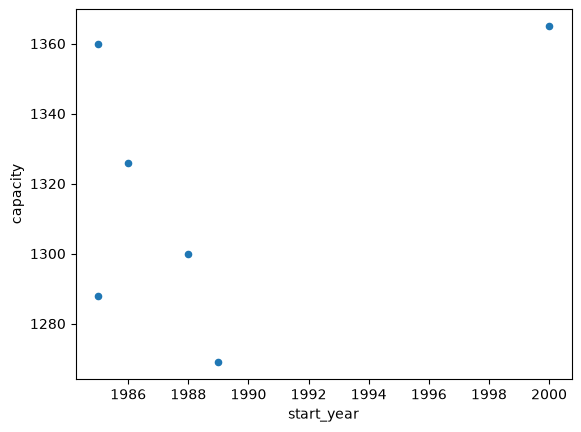

In [50]:
# Nuage de points : année de mise en service (x) et capacité (y)
df.plot(kind="scatter", x="start_year", y="capacity")

Text(0.5, 0, 'Capacité (MW)')

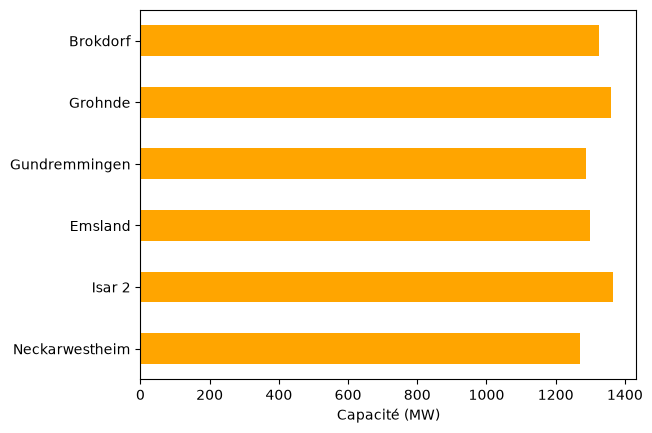

In [51]:
# Diagramme à barres horizontales de la capacité de chaque centrale
df.capacity.plot.barh(color="orange")
import matplotlib.pyplot as plt

# plt permet de compléter le graphique de pandas (ici le titre de l'axe)
plt.xlabel("Capacité (MW)")

## Index temporels

Les index sont très puissants : c'est une grande partie de ce qui rend Pandas utile. Il existe différents types d'index selon le type de données. Les index temporels sont particulièrement adaptés aux données qui dépendent du temps.

In [52]:
# date_range : une suite de dates régulières (freq="D" = un pas de temps par jour)
time = pd.date_range(start="2021-01-01", end="2023-01-01", freq="D")
# .dayofyear : numéro du jour dans l'année (1 à 365)
time.dayofyear

Index([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,
       ...
       357, 358, 359, 360, 361, 362, 363, 364, 365,   1],
      dtype='int32', length=731)

In [53]:
# Une sinusoïde de période un an, calculée pour chaque jour
values = np.sin(2 * np.pi * time.dayofyear / 365)
values

Index([ 0.017213356155834685,   0.03442161162274574,  0.051619667223253764,
         0.06880242680231986,   0.08596479873744647,   0.10310169744743485,
          0.1202080448993527,   0.13727877211326478,   0.15430882066428117,
          0.1712931441814776,
       ...
        -0.13727877211326517,  -0.12020804489935275,  -0.10310169744743544,
         -0.0859647987374467,  -0.06880242680232064,  -0.05161966722325418,
       -0.034421611622745804,  -0.01721335615583528, 6.432490598706546e-16,
        0.017213356155834685],
      dtype='float64', length=731)

In [54]:
values = np.sin(2 * np.pi * time.dayofyear / 365)
# Série temporelle : les valeurs sont indexées par les dates
ts = pd.Series(values, index=time)
ts

2021-01-01    1.721336e-02
2021-01-02    3.442161e-02
2021-01-03    5.161967e-02
2021-01-04    6.880243e-02
2021-01-05    8.596480e-02
                  ...     
2022-12-28   -5.161967e-02
2022-12-29   -3.442161e-02
2022-12-30   -1.721336e-02
2022-12-31    6.432491e-16
2023-01-01    1.721336e-02
Freq: D, Length: 731, dtype: float64

<Axes: >

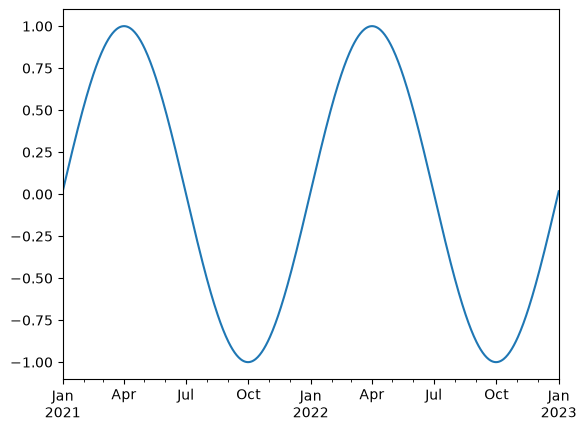

In [55]:
# Pour une série temporelle, plot() met automatiquement les dates en abscisse
ts.plot()

On peut utiliser la notation de _tranche_ de Python dans `.loc` pour sélectionner une plage de dates :

<Axes: >

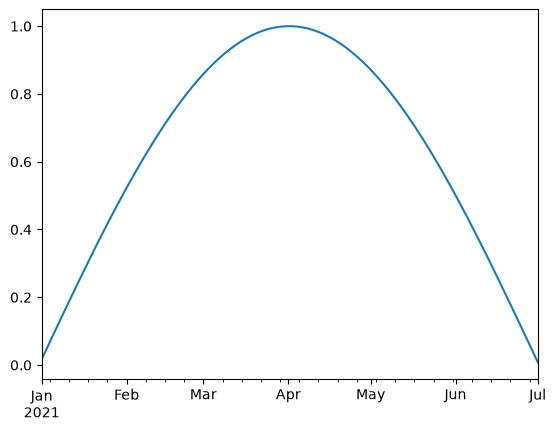

In [56]:
# Sélection d'une plage de dates avec une tranche sur .loc
ts.loc["2021-01-01":"2021-07-01"].plot()

<Axes: >

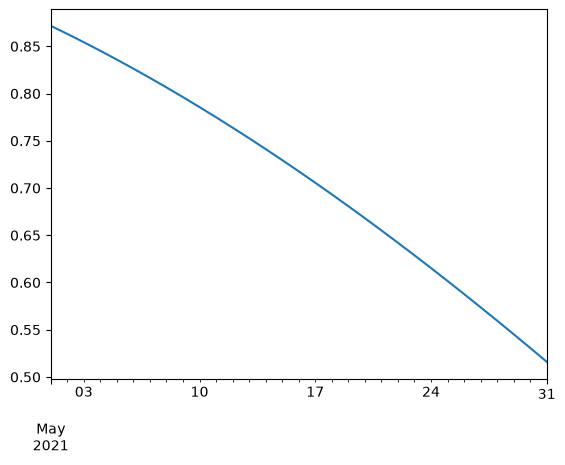

In [57]:
# Une chaîne partielle sélectionne toute une période (ici tout le mois de mai 2021)
ts.loc["2021-05"].plot()

L'objet `pd.DatetimeIndex` possède de nombreux attributs utiles :

In [58]:
# Numéro du mois (1 à 12) de chaque date
ts.index.month

Index([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       ...
       12, 12, 12, 12, 12, 12, 12, 12, 12,  1],
      dtype='int32', length=731)

In [59]:
# Jour de la semaine (0 = lundi, ..., 6 = dimanche)
ts.index.weekday

Index([4, 5, 6, 0, 1, 2, 3, 4, 5, 6,
       ...
       4, 5, 6, 0, 1, 2, 3, 4, 5, 6],
      dtype='int32', length=731)

Une autre opération courante consiste à **changer la résolution** d'un jeu de données par rééchantillonnage temporel. Pandas propose pour cela la fonction `.resample()`. Les périodes de rééchantillonnage s'écrivent avec la syntaxe des [alias de décalage](http://pandas.pydata.org/pandas-docs/stable/timeseries.html#offset-aliases).

Ci-dessous, on **rééchantillonne** la série en prenant la moyenne sur chaque mois.

In [60]:
# resample("12h").mean() : moyenne par tranche de 12 h ; comme on passe d'un pas journalier
# à un pas de 12 h, interpolate() comble les valeurs manquantes par interpolation linéaire
ts.resample("12h").mean().interpolate()

2021-01-01 00:00:00    1.721336e-02
2021-01-01 12:00:00    2.581748e-02
2021-01-02 00:00:00    3.442161e-02
2021-01-02 12:00:00    4.302064e-02
2021-01-03 00:00:00    5.161967e-02
                           ...     
2022-12-30 00:00:00   -1.721336e-02
2022-12-30 12:00:00   -8.606678e-03
2022-12-31 00:00:00    6.432491e-16
2022-12-31 12:00:00    8.606678e-03
2023-01-01 00:00:00    1.721336e-02
Freq: 12h, Length: 1461, dtype: float64

<Axes: >

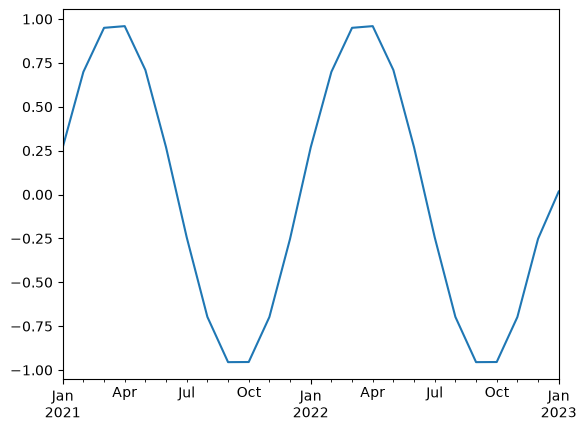

In [61]:
# Moyenne mensuelle ("ME" = fin de mois, Month End) puis tracé
ts.resample("ME").mean().plot()

## Lire et écrire des fichiers

Pour **lire** des données avec pandas, on peut utiliser par exemple la fonction [`pd.read_csv()`](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.read_csv.html). Cette fonction est puissante et possède de nombreuses options : elle permet de lire presque n'importe quel fichier texte.

La fonction `pd.read_csv()` accepte un chemin vers un fichier local ou même un lien hypertexte vers un fichier texte en ligne.

Importons un jeu de données un peu plus grand, qui décrit le parc de centrales électriques en Europe :

In [62]:
fn = "https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv"
# fn = "powerplants(4).csv"

In [63]:
# read_csv lit le fichier ; index_col=0 utilise la première colonne comme index
df = pd.read_csv(fn, index_col=0)

In [64]:
df = pd.read_csv(fn, index_col=0)
# iloc[:5, :10] : les 5 premières lignes et les 10 premières colonnes
df.iloc[:5, :10]

,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut
id,,,,,,,,,,
0,Obervermuntwerk Maschine Turbine,Hydro,Pumped Storage,Store,Austria,380.0,0.75,1943.0,2018.0,NaN
1,Cruachan,Hydro,Pumped Storage,Store,United Kingdom,440.0,NaN,1965.0,1965.0,NaN
2,Limmern,Hydro,Pumped Storage,Store,Switzerland,1352.0,NaN,1964.0,2016.0,NaN
3,Porabka Zar,Hydro,Pumped Storage,Store,Poland,552.0,NaN,1953.0,1998.0,NaN
4,Roncovalgrande,Hydro,Pumped Storage,Store,Italy,1000.0,NaN,1970.0,NaN,NaN


In [65]:
# Informations générales : types des colonnes, valeurs non nulles, mémoire utilisée
df.info()

<class 'pandas.DataFrame'>
Index: 302301 entries, 0 to 302814
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Name                 302301 non-null  str    
 1   Fueltype             302301 non-null  str    
 2   Technology           167809 non-null  str    
 3   Set                  301960 non-null  str    
 4   Country              302301 non-null  str    
 5   Capacity             302263 non-null  float64
 6   Efficiency           511 non-null     float64
 7   DateIn               297677 non-null  float64
 8   DateRetrofit         2594 non-null    float64
 9   DateOut              8441 non-null    float64
 10  lat                  302301 non-null  float64
 11  lon                  302301 non-null  float64
 12  Duration             6364 non-null    float64
 13  Volume_Mm3           1777 non-null    float64
 14  DamHeight_m          2041 non-null    float64
 15  StorageCapacity_MWh  7160 non-nul

In [66]:
# Statistiques descriptives des colonnes numériques
df.describe()

,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh
count,302263.000000,511.000000,297677.000000,2594.000000,8441.000000,302301.000000,302301.000000,6364.000000,1777.000000,2041.000000,7.160000e+03
mean,5.358940,0.491690,2015.054344,1986.755204,2022.834735,50.674953,9.837007,215.328174,206.617056,186.178177,1.353912e+04
std,58.138263,0.176997,11.204233,25.485336,4.574041,2.784949,3.662447,808.737070,991.347641,250.734724,1.228374e+05
min,0.010000,0.191434,1828.000000,1899.000000,1969.000000,32.647300,-51.716700,0.000005,0.001600,-99.000000,1.000000e-05
25%,0.080000,0.364189,2010.000000,1968.000000,2021.000000,48.999878,8.085533,1.200000,4.100000,33.800000,9.433050e-02
50%,0.160000,0.399300,2017.000000,1994.000000,2023.000000,50.996612,9.626321,1.984286,22.600000,94.000000,2.330000e-01
75%,0.875000,0.589750,2023.000000,2008.000000,2025.000000,52.388267,11.659744,2.509987,110.000000,251.500000,1.000000e+01
max,5400.000000,0.917460,2056.000000,2020.000000,2050.000000,78.230000,39.655350,16840.000000,25810.000000,3051.460000,4.869834e+06


On peut aussi vouloir **enregistrer** un DataFrame pour plus tard. De nombreux formats de fichiers existent pour les données tabulaires : HTML, JSON, Excel, Parquet, Feather, etc. Ici, on l'enregistre au format CSV (valeurs séparées par des virgules) sous le nom « tmp.csv ».

In [67]:
# Enregistre le DataFrame dans un fichier CSV local
df.to_csv("tmp.csv")

In [68]:
df

,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
0,Obervermuntwerk Maschine Turbine,Hydro,Pumped Storage,Store,Austria,380.0,0.75,1943.0,2018.0,NaN,46.935290,10.059950,71.573684,35.630769,291.00,27198.000000,set(),"{'MASTR': {'MASTR-SEE984944424651', 'MASTR-SEE..."
1,Cruachan,Hydro,Pumped Storage,Store,United Kingdom,440.0,NaN,1965.0,1965.0,NaN,56.406400,-5.113000,15.909091,11.300000,46.00,9680.000000,{'48WSTN00000CRUAC'},"{'GEM': {'G100000603737'}, 'EESI': {'EESI-1521..."
2,Limmern,Hydro,Pumped Storage,Store,Switzerland,1352.0,NaN,1964.0,2016.0,NaN,46.862550,8.999750,27.997365,25.000000,329.00,68000.000000,{'12W-0000000018-B'},"{'GEM': {'G100000603536', 'G100000603559'}, 'E..."
3,Porabka Zar,Hydro,Pumped Storage,Store,Poland,552.0,NaN,1953.0,1998.0,NaN,49.780300,19.211600,3.629764,28.910000,440.00,4000.000000,{'19W000000000247X'},"{'GEM': {'G100000603214'}, 'EESI': {'EESI-1471..."
4,Roncovalgrande,Hydro,Pumped Storage,Store,Italy,1000.0,NaN,1970.0,NaN,NaN,46.069400,8.732400,17.421260,10.000000,736.25,8000.000000,"{'26W-S03RNCVRONCH', '26WIMPI-S03RNCVS'}","{'GEM': {'G100000602249'}, 'EESI': {'EESI-1490..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302810,Taloro Deg Salto Benzone,Hydro,Reservoir,Store,Italy,32.7,NaN,NaN,NaN,NaN,40.127148,9.140644,272.313988,20.190000,241.00,8904.667391,"{nan, nan}","{'JRC': {'JRC-H3692', 'JRC-H3681'}}"
302811,Telessio Eugio Rosone,Hydro,Reservoir,Store,Italy,82.4,NaN,NaN,NaN,NaN,45.433313,7.417422,NaN,27.950000,1217.00,NaN,{nan},{'JRC': {'JRC-H3314'}}
302812,Valina Ca Zul,Hydro,Reservoir,Store,Italy,8.0,NaN,NaN,NaN,NaN,46.294781,12.711214,325.978125,11.000000,100.00,2607.825000,{nan},{'JRC': {'JRC-H3738'}}


## Regrouper et agréger

Les objets `Series` et `DataFrame` possèdent une méthode `groupby` qui permet de **regrouper et d'agréger** les données selon les valeurs d'une ou plusieurs colonnes.

Elle accepte de nombreux arguments, mais la façon la plus simple de la comprendre est de lui passer une autre série dont les valeurs uniques servent à découper l'objet d'origine en groupes.

Voici un exemple qui calcule la capacité de production totale par pays.

In [69]:
# Trois étapes enchaînées : groupby (découper par pays), .Capacity.sum() (additionner les capacités
# de chaque pays), sort_values puis head (garder les 10 premiers)
grouped = df.groupby("Country").Capacity.sum()
grouped.sort_values(ascending=False).head(10)

Country
Germany           401035.518269
United Kingdom    167248.179335
France            158571.368310
Spain             148501.152800
Italy             110548.948000
Poland             69304.666738
Ukraine            58396.200000
Sweden             54421.639817
Netherlands        48472.760000
Norway             40778.960000
Name: Capacity, dtype: float64

Enchaîner ainsi plusieurs opérations est très courant avec pandas.

Décomposons cette opération. Le travail avec `groupby` se fait en trois étapes :

1. **Découper (split)** : répartir les données en groupes selon un critère.
1. **Appliquer (apply)** : faire un calcul (agrégation ou transformation) au sein de chaque groupe.
1. **Combiner (combine)** : rassembler les résultats dans un seul objet.

<img src="https://miro.medium.com/max/1840/1*JbF6nhrQsn4f-TaSF6IR9g.png" width="720px" />

On peut aussi regrouper selon plusieurs colonnes. Par exemple, pour regrouper les capacités par pays **et** par type de combustible, on passe une liste de colonnes à `groupby`.

In [70]:
# Regroupement selon deux colonnes : l'index du résultat comporte deux niveaux (pays, combustible)
capacities = df.groupby(["Country", "Fueltype"]).Capacity.sum()
capacities

Country         Fueltype     
Albania         Battery             24.000000
                Hydro             2079.366000
                Solar              454.200000
                Wind               150.000000
Austria         Battery             73.920000
                                     ...     
United Kingdom  Oil                616.800000
                Solar            13742.797835
                Solid Biomass     4154.200000
                Waste             2073.050000
                Wind             39634.791500
Name: Capacity, Length: 328, dtype: float64

Quand on regroupe selon plusieurs attributs, l'index devient un `pd.MultiIndex` (un index hiérarchique à plusieurs *niveaux*).

In [71]:
# Les 5 premières entrées de l'index : ce sont des couples (pays, combustible)
capacities.index[:5]

MultiIndex([('Albania', 'Battery'),
            ('Albania',   'Hydro'),
            ('Albania',   'Solar'),
            ('Albania',    'Wind'),
            ('Austria', 'Battery')],
           names=['Country', 'Fueltype'])

In [72]:
# Le type de cet index : un MultiIndex (index hiérarchique)
type(capacities.index)

pandas.MultiIndex

In [73]:
# Les 10 plus petites valeurs de la colonne Capacity
df.nsmallest(10, "Capacity")

,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
26635,Balance,Hydrogen Storage,NaN,Store,Finland,0.01,NaN,NaN,NaN,NaN,64.961900,26.013300,NaN,NaN,NaN,0.12,{nan},{'EESI': {'EESI-153292'}}
26726,Dresden,Hydrogen Storage,NaN,Store,Germany,0.01,NaN,NaN,NaN,NaN,51.050100,13.738300,NaN,NaN,NaN,0.20,{nan},{'EESI': {'EESI-153397'}}
26795,From The Sun Brunate,Hydrogen Storage,NaN,Store,Italy,0.01,NaN,NaN,NaN,NaN,45.823300,9.094200,NaN,NaN,NaN,0.14,{nan},{'EESI': {'EESI-153340'}}
26796,Fronius Energy Cell Self Sufficient House,Hydrogen Storage,NaN,Store,Portugal,0.01,NaN,NaN,NaN,NaN,38.666700,-27.216700,NaN,NaN,NaN,0.18,{nan},{'EESI': {'EESI-153328'}}
26863,Hydrogen Village Burgenland,Hydrogen Storage,NaN,Store,Austria,0.01,NaN,NaN,NaN,NaN,47.517412,16.457275,NaN,NaN,NaN,0.21,{nan},{'EESI': {'EESI-153416'}}
26914,Laboratory System At Ife Kjeller Pahse,Hydrogen Storage,NaN,Store,Norway,0.01,NaN,NaN,NaN,NaN,60.063456,11.033456,NaN,NaN,NaN,0.28,"{nan, nan}","{'EESI': {'EESI-153360', 'EESI-153310'}}"
27024,Primolyzer,Hydrogen Storage,NaN,Store,Denmark,0.01,NaN,NaN,NaN,NaN,55.676097,12.568337,NaN,NaN,NaN,0.10,{nan},{'EESI': {'EESI-153354'}}
27032,Rabh,Hydrogen Storage,NaN,Store,United Kingdom,0.01,NaN,NaN,NaN,NaN,51.507400,-0.127800,NaN,NaN,NaN,0.10,{nan},{'EESI': {'EESI-153364'}}
27039,Regenerativer Energipark Ostfalia Hybrid Renew...,Hydrogen Storage,NaN,Store,Germany,0.01,NaN,NaN,NaN,NaN,52.133300,10.533300,NaN,NaN,NaN,0.12,{nan},{'EESI': {'EESI-153334'}}


La fonction `.unstack` permet de transformer la `Series` à index multiple en `DataFrame` dont le deuxième niveau d'index devient les colonnes.

In [74]:
# unstack : le niveau "combustible" passe en colonnes ; fillna(0.0) remplace les combinaisons absentes par 0 ;
# .T transpose pour avoir les pays en colonnes ; round(1) arrondit à une décimale
capacities.unstack().fillna(0.0).T.round(1)

Country,Albania,Austria,Belgium,Bosnia and Herzegovina,Bulgaria,Croatia,Czechia,Denmark,Estonia,Finland,...,Portugal,Romania,Serbia,Slovakia,Slovenia,Spain,Sweden,Switzerland,Ukraine,United Kingdom
Fueltype,,,,,,,,,,,,,,,,,,,,,
Battery,24.0,73.9,291.2,0.0,1397.7,1.0,43.0,155.9,135.5,300.6,...,58.1,843.9,0.0,5.3,62.6,292.9,764.5,73.5,201.0,7365.0
Biogas,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,535.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,0.0,101.5
Geothermal,0.0,0.0,0.0,0.0,0.0,56.1,0.0,0.0,0.0,0.0,...,24.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,2.0
Hard Coal,0.0,1471.0,2865.0,0.0,2704.0,342.0,1548.0,5055.0,0.0,3920.2,...,2028.0,1705.0,0.0,989.0,124.0,11204.6,291.0,0.0,23346.0,35856.6
Heat Storage,0.0,0.0,5.0,0.0,0.0,0.0,0.0,6.2,0.0,625.2,...,0.0,0.0,0.0,0.0,0.0,1049.5,0.0,0.0,0.0,0.0
Hydro,2079.4,15952.9,1380.0,2363.5,2902.7,2154.0,1841.6,0.0,0.0,3198.6,...,8486.2,7710.7,3656.3,2456.5,1216.1,18216.2,15308.6,18248.6,6600.7,4761.9
Hydrogen Storage,0.0,5.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,1.3,...,1.0,0.0,0.0,0.0,0.0,3.5,0.0,0.0,0.0,2.2
Lignite,0.0,522.0,0.0,2090.0,6057.0,0.0,9380.1,0.0,0.0,150.0,...,0.0,6104.0,4817.0,548.0,1480.0,2729.0,0.0,0.0,0.0,0.0
Mechanical Storage,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0


**En résumé,** le travail typique avec pandas consiste à lire des données depuis des fichiers, les inspecter et les nettoyer, les analyser par transformation et agrégation, visualiser les résultats, puis enregistrer les données traitées pour un usage ultérieur.

## Exercices

### Données sur les centrales électriques

Dans cet exercice, on utilise le jeu de données [powerplants.csv](https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv) du projet [powerplantmatching](https://github.com/PyPSA/powerplantmatching). Il contient des informations sur de nombreuses centrales : nom, pays, type de combustible, capacité, etc.

URL : `https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv`

**Question 1 :** Chargez le jeu de données dans un DataFrame pandas.

In [75]:
# TODO : charger le jeu de données des centrales dans un DataFrame nommé df_pp.
#  - afficher les premières lignes avec .head() pour vérifier la lecture.


,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
0,Obervermuntwerk Maschine Turbine,Hydro,Pumped Storage,Store,Austria,380.0,0.75,1943.0,2018.0,NaN,46.93529,10.05995,71.573684,35.630769,291.00,27198.0,set(),"{'MASTR': {'MASTR-SEE984944424651', 'MASTR-SEE..."
1,Cruachan,Hydro,Pumped Storage,Store,United Kingdom,440.0,NaN,1965.0,1965.0,NaN,56.40640,-5.11300,15.909091,11.300000,46.00,9680.0,{'48WSTN00000CRUAC'},"{'GEM': {'G100000603737'}, 'EESI': {'EESI-1521..."
2,Limmern,Hydro,Pumped Storage,Store,Switzerland,1352.0,NaN,1964.0,2016.0,NaN,46.86255,8.99975,27.997365,25.000000,329.00,68000.0,{'12W-0000000018-B'},"{'GEM': {'G100000603536', 'G100000603559'}, 'E..."
3,Porabka Zar,Hydro,Pumped Storage,Store,Poland,552.0,NaN,1953.0,1998.0,NaN,49.78030,19.21160,3.629764,28.910000,440.00,4000.0,{'19W000000000247X'},"{'GEM': {'G100000603214'}, 'EESI': {'EESI-1471..."
4,Roncovalgrande,Hydro,Pumped Storage,Store,Italy,1000.0,NaN,1970.0,NaN,NaN,46.06940,8.73240,17.421260,10.000000,736.25,8000.0,"{'26W-S03RNCVRONCH', '26WIMPI-S03RNCVS'}","{'GEM': {'G100000602249'}, 'EESI': {'EESI-1490..."


**Question 2 :** Appliquez la fonction `.describe()` au DataFrame.

In [76]:
# TODO : afficher les statistiques descriptives des colonnes numériques du DataFrame (méthode .describe()).


,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh
count,302263.000000,511.000000,297677.000000,2594.000000,8441.000000,302301.000000,302301.000000,6364.000000,1777.000000,2041.000000,7.160000e+03
mean,5.358940,0.491690,2015.054344,1986.755204,2022.834735,50.674953,9.837007,215.328174,206.617056,186.178177,1.353912e+04
std,58.138263,0.176997,11.204233,25.485336,4.574041,2.784949,3.662447,808.737070,991.347641,250.734724,1.228374e+05
min,0.010000,0.191434,1828.000000,1899.000000,1969.000000,32.647300,-51.716700,0.000005,0.001600,-99.000000,1.000000e-05
25%,0.080000,0.364189,2010.000000,1968.000000,2021.000000,48.999878,8.085533,1.200000,4.100000,33.800000,9.433050e-02
50%,0.160000,0.399300,2017.000000,1994.000000,2023.000000,50.996612,9.626321,1.984286,22.600000,94.000000,2.330000e-01
75%,0.875000,0.589750,2023.000000,2008.000000,2025.000000,52.388267,11.659744,2.509987,110.000000,251.500000,1.000000e+01
max,5400.000000,0.917460,2056.000000,2020.000000,2050.000000,78.230000,39.655350,16840.000000,25810.000000,3051.460000,4.869834e+06


**Question 3 :** Donnez la liste des types de combustibles et des technologies (valeurs uniques) présents dans le jeu de données (quelques fonctions de la documentation pourraient être utiles)


In [77]:
# TODO : obtenir les types de combustibles et les technologies présents dans les données.


(['Battery',
  'Biogas',
  'Geothermal',
  'Hard Coal',
  'Heat Storage',
  'Hydro',
  'Hydrogen Storage',
  'Lignite',
  'Mechanical Storage',
  'Natural Gas',
  'Nuclear',
  'Oil',
  'Other',
  'Solar',
  'Solid Biomass',
  'Waste',
  'Wind'],
 ['CAES',
  'CCGT',
  'CSP',
  'Combustion Engine',
  'Csp',
  'Fe',
  'Flywheel',
  'Laes',
  'Li',
  'Molten Salt',
  'NaNiCl',
  'NaS',
  'NiCd',
  'OCGT',
  'Offshore',
  'Onshore',
  'PV',
  'Pb',
  'Pumped Storage',
  'Reservoir',
  'Run-Of-River',
  'Steam Turbine',
  'V'])

**Question 4 :** Filtrez le jeu de données pour ne garder que les centrales dont le combustible est « Hard Coal » (houille).

In [78]:
# TODO : ne garder que les centrales dont le combustible (colonne Fueltype) est "Hard Coal".


,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
103,Heilbronn,Hard Coal,Steam Turbine,CHP,Germany,1034.5,0.448108,1958.0,2010.0,2030.0,49.174810,9.208312,NaN,NaN,NaN,NaN,{'11WD4HLBR1CS---A'},"{'MASTR': {'MASTR-SEE968847258773', 'MASTR-SEE..."
104,Rheinhafen Dampfkraftwerk,Hard Coal,Steam Turbine,CHP,Germany,1351.0,0.451390,1955.0,2014.0,2031.0,49.012740,8.304255,NaN,NaN,NaN,NaN,{'11WD4DAXLA-S---T'},"{'MASTR': {'MASTR-SEE980016033738', 'MASTR-SEE..."
133,Bergkamen,Hard Coal,Steam Turbine,CHP,Germany,720.0,0.377500,1981.0,1981.0,2028.0,51.636945,7.619083,NaN,NaN,NaN,NaN,{'11WD7BERG1S--KWB'},"{'MASTR': {'MASTR-SEE930673793902'}, 'GEM': {'..."
134,Datteln,Hard Coal,Steam Turbine,CHP,Germany,1052.0,0.339662,1964.0,1969.0,2038.0,51.633130,7.342480,NaN,NaN,NaN,NaN,{'11W0-0000-0043-Z'},"{'MASTR': {'MASTR-SEE913516809497'}, 'GEM': {'..."
135,Bexbach,Hard Coal,Steam Turbine,CHP,Germany,726.0,0.382500,1983.0,1983.0,2031.0,49.361390,7.237308,NaN,NaN,NaN,NaN,"{'11WD7MITB1C----N', '11WD7MITB1S--KWK'}","{'MASTR': {'MASTR-SEE954971534470'}, 'GEM': {'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302734,Poznan Garbary,Hard Coal,NaN,CHP,Poland,20.0,NaN,1929.0,NaN,2015.0,52.414100,16.944900,NaN,NaN,NaN,NaN,"{nan, nan}","{'BEYONDCOAL': {'BEYOND-PL-158-2', 'BEYOND-PL-..."
302735,Scholven Buer Scholven,Hard Coal,NaN,CHP,Germany,2220.0,NaN,1968.0,NaN,2031.0,51.602400,7.009900,NaN,NaN,NaN,NaN,"{nan, nan, nan, nan, nan}","{'BEYONDCOAL': {'BEYOND-DE-100-1', 'BEYOND-DE-..."
302736,Stalowa Wola,Hard Coal,NaN,CHP,Poland,250.0,NaN,1958.0,NaN,2021.0,50.550000,22.066700,NaN,NaN,NaN,NaN,"{nan, nan}","{'BEYONDCOAL': {'BEYOND-PL-187-6', 'BEYOND-PL-..."


**Question 5 :** Identifiez les 5 plus grandes centrales à charbon. Dans quels pays se trouvent-elles ? Quand ont-elles été construites ?

In [79]:
# TODO : trouver les 5 plus grandes centrales à charbon, avec leur pays et leur année de mise en service.

,Country,Fueltype,Technology,Capacity,DateIn
id,,,,,
823,United Kingdom,Hard Coal,Steam Turbine,4206.0,1974.0
501,Poland,Hard Coal,Steam Turbine,3332.0,1993.0
138,Poland,Hard Coal,Steam Turbine,2919.0,1972.0
2190,Ukraine,Hard Coal,Steam Turbine,2643.0,1963.0
3269,Italy,Hard Coal,Steam Turbine,2640.0,1991.0


**Question 6 :** Identifiez la centrale dont le nom est le plus long.

In [80]:
# TODO : trouver la centrale dont le nom (l'index du DataFrame) est le plus long.


('100000', 6)

**Question 7 :** Identifiez les 10 centrales les plus au nord. De quel type de centrales s'agit-il ?

In [81]:
# TODO : trouver les 10 centrales les plus au nord, et leur type.


,Country,Fueltype,Technology,lat,lon
id,,,,,
26935,Norway,Battery,NaN,78.230000,15.620000
5221,Norway,Wind,Onshore,71.012300,24.594200
5217,Norway,Wind,Onshore,70.918500,27.289900
1809,Norway,Hydro,Reservoir,70.773547,25.616486
3597,Norway,Wind,Onshore,70.765700,29.083300
26831,Norway,Hydrogen Storage,NaN,70.765175,29.083687
3435,Norway,Hydro,Reservoir,70.751421,27.355047
7568,Norway,Natural Gas,CCGT,70.689366,23.600448
17605,Norway,Natural Gas,CCGT,70.685400,23.590000


**Question 8 :** Quelle est l'année moyenne de mise en service de chaque type de combustible ? Triez les types de combustible par année moyenne croissante et arrondissez à l'entier le plus proche.

In [82]:
# TODO : calculer l'année moyenne de mise en service (colonne DateIn) de chaque type de combustible.


Fueltype
Hydrogen Storage    1970
Hard Coal           1971
Hydro               1974
Lignite             1979
Nuclear             1980
Other               2003
Oil                 2004
Geothermal          2004
Waste               2005
Solid Biomass       2008
Biogas              2012
Wind                2013
Natural Gas         2014
Solar               2017
Battery             2024
Name: DateIn, dtype: int64

### Facteurs de charge éolien et solaire

Dans cet exercice, on travaille avec une série temporelle de facteurs de charge horaires éolien et solaire pour l'Irlande, issue de [model.energy](https://model.energy). Téléchargez les données localement ou passez par l'URL

**Question 1 :** Utilisez `pd.read_csv` pour charger le jeu de données depuis l'URL suivante dans un DataFrame pandas. Veillez à ce que les horodatages soient traités comme un `pd.DatetimeIndex`.

In [83]:
# TODO : charger la série temporelle des facteurs de charge de l'Irlande dans un DataFrame df_ts.


**Question 2 :** Calculez le facteur de charge moyen de l'éolien et du solaire sur toute la période.

In [84]:
# TODO : calculer le facteur de charge moyen de l'éolien et du solaire sur toute la période.


NameError: name 'df_ts' is not defined

**Question 3 :** Calculez la corrélation entre les facteurs de charge éolien et solaire.

:::{note}
Consultez la [documentation de pandas](https://pandas.pydata.org/pandas-docs/stable/index.html) pour trouver les fonctions utiles à ces questions.
:::

In [ ]:
# TODO : calculer la corrélation entre les facteurs de charge éolien et solaire (méthode .corr()).


**Question 4 :** Tracez les facteurs de charge éolien et solaire pour le mois de mai.

In [ ]:
# TODO : tracer les facteurs de charge éolien et solaire du mois de mai.


**Question 5 :** Tracez les facteurs de charge moyens hebdomadaires éolien et solaire sur toute la période.

In [ ]:
# TODO : tracer la moyenne hebdomadaire des facteurs de charge sur toute la période.


**Question 6 :** Rendez-vous sur [model.energy](https://model.energy) et récupérez les séries temporelles d'une autre région de votre choix. Refaites l'analyse précédente et comparez les résultats.

In [ ]:
# TODO : reprendre l'analyse (moyenne, corrélation, graphiques) pour une autre région de model.energy.
#  - charger le CSV de cette région dans df_other puis réutiliser les mêmes instructions.

# Geopandas et Cartopy

In [ ]:
import warnings

warnings.filterwarnings("ignore")

## Pourquoi pas seulement `pandas` ?

Rechargeons notre jeu de données d'exemple des centrales conventionnelles en Europe sous forme de `pd.DataFrame`.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

fn = "https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv"
exclude_carriers = ["Wind", "Solar", "Solid Biomass", "Biogas"]
ppl = pd.read_csv(fn, index_col=0).query(
    "Fueltype not in @exclude_carriers and Capacity > 20"
)

Ce jeu de données contient des coordonnées (latitude et longitude), ce qui permet de représenter l'emplacement et la capacité de toutes les centrales sur un nuage de points :

In [ ]:
ppl.plot.scatter("lon", "lat", s=ppl.Capacity / 1e3)

Mais ce graphique manque de **repères géographiques** que l'on attend normalement d'une carte : côtes, frontières entre pays, etc.

## Pourquoi `geopandas` ?

<img src="https://geopandas.org/en/stable/_images/geopandas_logo.png" width="400px" />

Geopandas étend `pandas` en ajoutant la prise en charge des données géospatiales.

La structure de données centrale de GeoPandas est la `geopandas.GeoDataFrame`, une sous-classe de `pandas.DataFrame` qui peut stocker des colonnes de géométries et effectuer des opérations spatiales.

<img src="https://geopandas.org/en/stable/_images/dataframe.svg" width="600px" />

:::{note}
La documentation de ce paquet est disponible sur https://geopandas.org/en/stable/.
:::

Les géométries typiques sont les points, les lignes et les polygones. Elles proviennent d'une autre bibliothèque, [`shapely`](https://shapely.readthedocs.io/en/stable/manual.html), qui permet de créer, d'analyser et de manipuler des formes en deux dimensions et leurs propriétés (points, lignes, polygones).

On commence par importer le paquet `geopandas`. L'alias conventionnel est `gpd` :

In [ ]:
import geopandas as gpd

On peut convertir les valeurs de latitude et de longitude du jeu de données en géométries à proprement parler (plus exactement des objets `shapely.Point`) avec la fonction `gpd.points_from_xy()`, puis s'en servir pour créer une `gpd.GeoDataFrame`. Il faut aussi préciser un *système de coordonnées de référence* (CRS). Le code `4326` désigne des valeurs de latitude et de longitude, c'est-à-dire le système WGS84.

In [ ]:
geometry = gpd.points_from_xy(ppl["lon"], ppl["lat"])
geometry[:5]

In [ ]:
gdf = gpd.GeoDataFrame(ppl, geometry=geometry, crs=4326)

La `gdf` obtenue ressemble maintenant à ceci :

In [ ]:
gdf.head(3)

In [ ]:
gdf.geometry.head()

Grâce à la colonne `geometry` supplémentaire, il est encore plus facile de **tracer** des données géographiques :

In [ ]:
gdf.plot(
    column="Fueltype",
    markersize=gdf.Capacity / 1e2,
)

On peut aussi lancer une **carte interactive** pour explorer plus en détail les données géographiques :

In [ ]:
gdf.explore(column="Fueltype")

## Les projections avec `cartopy`

<img src="https://scitools.org.uk/cartopy/docs/v0.16/_images/sphx_glr_logo_001.png" width="300px" />

Cartopy est un paquet Python conçu pour le traitement de données géospatiales ; il fournit une interface pour gérer les projections dans les cartes `matplotlib`.

**Pourquoi en a-t-on besoin ?**

La Terre est un globe, mais on présente généralement les cartes sur des surfaces à deux dimensions. Il faut donc *projeter* les points sur une surface plane (écran, papier). On perd toujours de l'information en le faisant.

<img src="https://raw.githubusercontent.com/SciTools/cartopy-tutorial/master/static/orange_peel.jpg" width="500px" />

Une projection cartographique est :

> une transformation systématique des latitudes et longitudes de lieux de la surface d'une sphère ou d'un ellipsoïde en positions sur un plan. [Wikipédia : Projection cartographique](https://fr.wikipedia.org/wiki/Projection_cartographique).

Chaque projection **conserve des propriétés métriques différentes**. Convertir des données d'une projection à une autre est donc un exercice courant en science des données géographiques.

- les **projections conformes** conservent les angles et les directions (par exemple la projection de Mercator) ;
- les **projections équivalentes** (à aires égales) conservent les surfaces (par exemple Mollweide) ;
- les **projections équidistantes** conservent les distances entre points (par exemple la plate carrée) ;
- les **projections de compromis** cherchent un équilibre entre les déformations (par exemple Robinson).

Si l'analogie de l'orange pour la Terre vous parle, regardez [cette vidéo de Numberphile](https://www.youtube.com/watch?v=D3tdW9l1690) avec Hannah Fry.

:::{note}
La documentation de ce paquet est disponible sur https://scitools.org.uk/cartopy/docs/latest/.
:::

On commence par importer les parties utiles du paquet `cartopy` :

In [ ]:
import cartopy
import cartopy.crs as ccrs

Traçons une première carte avec `cartopy` qui dessine les côtes du monde dans la [projection plate carrée (équirectangulaire)](https://fr.wikipedia.org/wiki/Projection_équirectangulaire) :

In [ ]:
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()

:::{note}
La liste des projections disponibles se trouve sur la [page des projections de Cartopy](https://scitools.org.uk/cartopy/docs/latest/reference/projections.html#cartopy-projections).
:::

On peut combiner `cartopy` avec les graphiques de `geopandas` et ajouter des [éléments géographiques](https://scitools.org.uk/cartopy/docs/latest/matplotlib/feature_interface.html#the-cartopy-feature-interface) :

In [ ]:
fig = plt.figure(figsize=(7, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

gdf.plot(
    ax=ax,
    column="Fueltype",
    markersize=gdf.Capacity / 1e2,
)

ax.coastlines()

ax.add_feature(cartopy.feature.BORDERS, color="red", linewidth=0.5)

ax.add_feature(cartopy.feature.OCEAN, color="blue")

ax.add_feature(cartopy.feature.LAND, color="yellow");

Geopandas calcule automatiquement des bornes raisonnables pour le graphique à partir des données géographiques.
On peut aussi zoomer ou dézoomer manuellement en fixant l'emprise spatiale avec la méthode `.set_extent()` :

In [ ]:
ax.set_extent([5, 16, 47, 55])
fig

### Reprojeter une `GeoDataFrame`

Dans `geopandas`, la fonction `.to_crs()` convertit une `GeoDataFrame` d'une projection donnée vers un autre système de coordonnées cible, en utilisant un objet CRS de `cartopy` :

In [ ]:
crs = ccrs.Orthographic()
print(crs)

In [ ]:
gdf.to_crs(crs).geometry.head()

In [ ]:
fig = plt.figure(figsize=(7, 7))

ax = plt.axes(projection=crs)

gdf.to_crs(crs).plot(
    ax=ax,
    column="Fueltype",
    markersize=gdf.Capacity / 1e2,
)

ax.coastlines()

## Lire et écrire des fichiers

Dans l'exemple suivant, on charge un jeu de données contenant les [régions NUTS](https://fr.wikipedia.org/wiki/Nomenclature_des_unités_territoriales_statistiques) :

> La nomenclature des unités territoriales statistiques (NUTS) est une norme de géocodes qui permet de référencer les subdivisions des pays à des fins statistiques.

Notre **objectif** final pour cette partie est d'associer la capacité de chaque centrale à la région NUTS-1 à laquelle elle appartient.

<img src="https://ec.europa.eu/eurostat/documents/345175/501899/framing" width="400px" />

Les formats courants pour les données géospatiales vectorielles sont GeoPackage (`.gpkg`), GeoJSON (`.geojson`), File Geodatabase (`.gdb`) ou Shapefile (`.shp`).

Dans `geopandas`, la fonction `gpd.read_file()` permet de lire ces fichiers. Commençons :

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/RHZJrN8Dnfn26nr/download/NUTS_RG_10M_2021_4326.geojson"

In [ ]:
nuts = gpd.read_file(url)

In [ ]:
nuts.head(3)

Il est recommandé de définir un index. On peut utiliser `.set_index()` pour cela :

In [ ]:
nuts = nuts.set_index("id")

On peut aussi examiner les géométries du jeu de données avec `.geometry` :

In [ ]:
nuts.geometry

L'attribut `.crs` indique dans quel système de coordonnées de référence les données sont exprimées :

In [ ]:
nuts.crs

L'attribut `.total_bounds` donne la boîte englobante des données, dans le système de coordonnées d'origine :

In [ ]:
nuts.total_bounds

Filtrons maintenant la GeoDataFrame au niveau NUTS-1...

In [ ]:
nuts1 = nuts.query("LEVL_CODE == 1")

... et regardons quels types de géométries le jeu de données contient ...

In [ ]:
nuts1.explore()

:::{note}
En principe, la `geopandas.GeoDataFrame` se comporte comme un `pandas.DataFrame` ordinaire : on peut utiliser toutes les fonctions de pandas que l'on connaît, plus les extensions géospatiales.
:::

Pour écrire une GeoDataFrame dans un fichier, on utilise `GeoDataFrame.to_file()`. Le format du fichier est déduit de son extension.

In [ ]:
nuts1.to_file("tmp.geojson")

In [ ]:
import os

os.remove("tmp.geojson")

## Tampons et surfaces

De nombreuses analyses géospatiales exigent de calculer des surfaces ou des tampons (zones autour de géométries). Or ces calculs dépendent du système de coordonnées utilisé.

La première chose à faire pour calculer une surface ou un tampon est de reprojeter la `GeoDataFrame` vers une projection à aires égales (ici : [EPSG:3035](https://epsg.io/3035), valable uniquement en Europe ; une alternative valable dans le monde entier est la projection de Mollweide [EPSG:54009](https://epsg.io/54009)).

In [ ]:
nuts1 = nuts1.to_crs(3035)

La surface est accessible avec `.area` et exprimée en m² (après projection). Convertissons-la en km² :

In [ ]:
area = nuts1.area / 1e6
area.head()

In [ ]:
nuts1.explore(column=area, vmax=1e5)

On peut aussi construire un tampon de 1 km autour de chaque géométrie avec `.buffer()` :

In [ ]:
nuts1.buffer(1000).explore()

On peut aussi calculer le centroïde de chaque géométrie, c'est-à-dire le centre géométrique d'une forme. C'est utile pour placer des étiquettes ou pour construire une représentation en réseau de points à partir de polygones :

In [ ]:
ax = nuts1.geometry.plot()
nuts1.representative_point().plot(ax=ax, color="red", markersize=2)

Pour calculer la distance entre deux points (ou plus généralement deux géométries), on utilise la méthode `.distance()`.
Par exemple, avec la méthode `nuts1.representative_point()`, on obtient un point central qui représente chaque géométrie mais qui, contrairement au centroïde, est garanti de se trouver à l'intérieur de la géométrie. Attention : la distance n'a de sens que si les géométries sont dans un système de coordonnées projeté adapté (par exemple une projection équidistante) :

In [ ]:
nuts1_de = nuts1.query("CNTR_CODE == 'DE'")
points = nuts1_de.representative_point()

ax = nuts1_de.plot()
points.plot(ax=ax, color="red", markersize=5)

In [ ]:
distances = (
    pd.concat({k: points.distance(p) for k, p in points.items()}, axis=1)
    .div(1e3)
    .astype(int)
)  # km
distances

La fonction `.distance()` calcule la distance dans le système de coordonnées de la `GeoDataFrame`. Pour des distances à la surface de la Terre à partir de latitudes et de longitudes, on utilise la formule de haversine, qui donne la distance orthodromique (« grand cercle ») entre deux points.

:::{note}
Voir aussi https://fr.wikipedia.org/wiki/Formule_de_haversine
:::

## Dissoudre (*dissolve*)

La fonction `.dissolve()` agrège les géométries d'une `GeoDataFrame` selon un ou plusieurs attributs. En pratique, elle est très proche de `pandas.DataFrame.groupby()`, mais au lieu d'agréger des valeurs numériques, elle fusionne des géométries.

Par exemple, on peut dissoudre les régions NUTS par code pays pour obtenir les géométries des pays :

In [ ]:
nuts1.dissolve("CNTR_CODE")  # .plot()

## Jointures spatiales

Plusieurs `GeoDataFrames` peuvent être combinées par des *jointures spatiales*.

Les observations de deux jeux de données sont associées avec la fonction [`.sjoin()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html) en fonction de leur relation spatiale (par exemple, se chevaucher, s'intersecter ou être contenues l'une dans l'autre). On trouvera plus de détails sur les options [ici](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html#binary-predicate-joins).

<img src="https://pythongis.org/_images/spatial-relations.png" width="800px" />

*Source : https://pythongis.org*

Pour effectuer une jointure spatiale, il faut fournir :

- les **deux objets `geopandas.GeoDataFrame`** à joindre (par exemple `left_df` et `right_df`) ;
- le **type de relation spatiale** à tester (par exemple `intersects`, `contains`, `within`), précisé avec le paramètre `predicate` ;
- le **type de jointure** à effectuer (par exemple `inner`, `left`, `right`), précisé avec le paramètre `how`. Avec `left`, la GeoDataFrame résultante conserve tous les enregistrements de `left_df`, auxquels s'ajoutent les enregistrements correspondants de `right_df` lorsque la relation spatiale est vérifiée. Avec `inner`, seuls les enregistrements ayant une correspondance dans les deux GeoDataFrames sont conservés. Avec `right`, tous les enregistrements de `right_df` sont conservés, avec les enregistrements correspondants de `left_df` quand ils existent.

La fonction [`.sjoin()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html) parcourt alors les géométries des deux GeoDataFrames, évalue la relation spatiale demandée et joint les enregistrements qui correspondent (en coulisses, elle utilise un [index spatial](https://fr.wikipedia.org/wiki/Base_de_données_spatiales) pour accélérer le calcul).

Par exemple, si le paramètre `predicate` vaut `'intersects'`, la fonction teste si la géométrie de chaque enregistrement de `left_df` coupe celle d'un enregistrement de `right_df`. Si c'est le cas, les attributs des deux enregistrements sont combinés en un nouvel enregistrement de la GeoDataFrame résultante.

<img src="https://pythongis.org/_images/spatial-join-basic-idea.png" width="800px" />

*Source : https://pythongis.org*

Le résultat d'une jointure spatiale est une nouvelle `GeoDataFrame` qui conserve les géométries de `left_df` et contient les attributs des deux GeoDataFrames pour les enregistrements qui correspondent.

Quand aucune correspondance n'est trouvée, les attributs issus de `right_df` valent `NaN` (par exemple pour les centrales situées en dehors des régions NUTS-1).

Prenons un **exemple**. On commence par reprojeter l'objet `gdf` des centrales dans le même CRS que les polygones `nuts1`, puis on le restreint aux centrales à charbon :

In [ ]:
gdf = gdf.to_crs(3035).query("Fueltype == 'Nuclear'")

Regardons ensuite les deux jeux de données ensemble. On veut déterminer quels points *(les centrales)* se trouvent dans quelles formes *(les régions NUTS-1)*.

In [ ]:
fig = plt.figure(figsize=(7, 7))

ax = plt.axes(projection=ccrs.epsg(3035))

nuts1.plot(ax=ax, edgecolor="black", facecolor="sandybrown")

gdf.to_crs(3035).plot(
    ax=ax, column="Fueltype", markersize=gdf.Capacity / 40, legend=True
)

ax.set_extent([-7, 24, 40, 62])

On peut maintenant appliquer la fonction `.sjoin()`. Par défaut, `.sjoin()` recherche les intersections et conserve les géométries de la `GeoDataFrame` de *gauche*.

In [ ]:
joined = gdf.sjoin(nuts1)

Si l'on regarde cette nouvelle `GeoDataFrame`, on voit des colonnes supplémentaires issues des données NUTS-1 :

In [ ]:
joined.head(3)

On peut maintenant utiliser ces nouvelles colonnes pour des opérations `.groupby()` sur les capacités (ainsi que pour trier, convertir les valeurs dans une unité adaptée et renommer l'index en remplaçant les identifiants NUTS par les noms des régions) :

In [ ]:
cap = joined.groupby("NUTS_ID").Capacity.sum().sort_values(ascending=False) / 1000  # GW
cap.rename(nuts1.NUTS_NAME).head(3)

Avec l'intersection et la jointure à gauche, certaines régions NUTS-1 disparaissent de `cap` car elles n'ont aucune centrale. On corrige cela en réindexant `cap` sur l'ensemble des régions NUTS-1 :

In [ ]:
nuts1.index.difference(cap.index)

In [ ]:
cap = cap.reindex(nuts1.index)
cap.head(3)

De plus, certaines centrales peuvent se trouver en dehors des régions NUTS-1 (par exemple celles d'Ukraine). La capacité totale de `cap` est donc inférieure à celle de `gdf`.

In [ ]:
cap.sum() < gdf.Capacity.div(1e3).sum()

Enfin, on peut tracer sur une carte la capacité totale de production à partir de houille par région NUTS-1.
Pour les régions sans centrale à charbon, le paramètre `missing_kwds` permet de choisir une apparence particulière (ici des hachures rouges).

In [ ]:
fig = plt.figure(figsize=(7, 7))

ax = plt.axes(projection=ccrs.epsg(3035))

nuts1.plot(
    ax=ax,
    column=cap,
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
    },
    legend_kwds={"label": "Hard Coal Capacity [GW]", "shrink": 0.7},
)

ax.set_extent([-7, 24, 40, 62])

Ceci conclut le tutoriel sur `geopandas` et `cartopy` !

:::{note}
Le point essentiel à retenir : aligner les systèmes de coordonnées de référence (les projections) est indispensable pour combiner des données issues de différents jeux de données géospatiaux.
:::

## Exercices

Prenez le code suivant comme point de départ. Il charge les régions NUTS de l'Europe, le jeu de données des centrales, et un shapefile des zones de protection de la nature danoises [Natura 2000](https://fr.wikipedia.org/wiki/Natura_2000).

```python
import cartopy
import pandas as pd
import geopandas as gpd
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

url = "https://tubcloud.tu-berlin.de/s/RHZJrN8Dnfn26nr/download/NUTS_RG_10M_2021_4326.geojson"
nuts = gpd.read_file(url)

fn = "https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv"
df = pd.read_csv(fn, index_col=0)
geometry = gpd.points_from_xy(df["lon"], df["lat"])
ppl = gpd.GeoDataFrame(df, geometry=geometry, crs=4326)

url = "https://tubcloud.tu-berlin.de/s/mEpdmgBtmMbyjAr/download/Natura2000_end2021-DK.gpkg"
natura = gpd.read_file(url)
```

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 1 :** Identifiez le système de coordonnées de référence de la `GeoDataFrame` `natura`.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 2 :** Tracez la `GeoDataFrame` `natura` sur une carte sans transformer son CRS. Utilisez `cartopy` pour définir la projection de la figure et ajoutez les côtes et les frontières.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 3 :** Identifiez le nom de la plus grande zone protégée de la `GeoDataFrame` `natura`.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 4 :** Quelle est la surface totale des zones protégées, en kilomètres carrés ?

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 5 :** La `GeoDataFrame` `natura` possède une colonne `SITETYPE` qui indique le type de zone protégée. Calculez la surface totale de chaque type de zone protégée (toujours en kilomètres carrés).

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 6 :** De combien (en pourcentage) la surface totale des zones protégées augmenterait-elle si l'on protégeait aussi un tampon de 1 km autour de chaque zone protégée ?

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 7 :** Listez les centrales situées dans des zones protégées. Combien y en a-t-il ? Utilisez la fonction [`.sjoin()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html). Vérifiez le résultat en traçant ces centrales au-dessus des zones protégées.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


**Question 8 (avancée) :** Quelle fraction de la surface de protection de la nature se situe en mer ? Utilisez des opérations ensemblistes avec la fonction [`.overlay()`](https://geopandas.org/en/stable/docs/user_guide/set_operations.html#set-operations-with-overlay) et la `GeoDataFrame` des régions NUTS.

:::{note}
Consultez la [documentation de GeoPandas](https://geopandas.org/en/stable/docs/user_guide/index.html) pour une introduction à l'utilisation de la fonction `.overlay()`.
:::

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


---

# Partie 3. Rasterio et atlite

Les explications, exemples guidés et exercices du notebook source sont conservés dans leur ordre d’origine.

# Atlite et Rasterio

:::{dropdown} Vidéo YouTube
:::{iframe} https://www.youtube.com/embed/6Z4NSBnc0V4
:width: 100%
La vidéo ne s'affiche pas ? Cliquez [ici](https://www.youtube.com/watch?v=6Z4NSBnc0V4).
:::

Dans ce tutoriel, nous présentons deux nouveaux paquets Python :

**Rasterio : accès aux données géospatiales matricielles (raster)**

> Les systèmes d'information géographique utilisent GeoTIFF et d'autres formats pour organiser et stocker des jeux de données matriciels (grilles) comme les images satellite et les modèles de terrain. Rasterio lit et écrit ces formats et fournit une API Python fondée sur les tableaux N-dimensionnels de Numpy et sur GeoJSON.

:::{note}
La documentation de rasterio est disponible sur https://rasterio.readthedocs.io/en/latest/index.html.
:::

**Atlite : convertir des données météorologiques en données de systèmes énergétiques**

> Atlite est une bibliothèque Python libre, fondée sur xarray, qui convertit des données météorologiques (vitesse du vent, rayonnement solaire, température, ruissellement) en données de systèmes électriques (séries temporelles de production éolienne, solaire, hydraulique et de demande de chaleur).

:::{note}
La documentation d'atlite est disponible sur https://atlite.readthedocs.io/en/latest/.

Cet outil est développé à la TU Berlin, dans le groupe « Digital Transformation of Energy Systems ».
:::

:::{note}
Si Python n'est pas encore installé sur votre ordinateur, vous pouvez exécuter ce TD dans votre navigateur avec [Google Colab](https://colab.research.google.com/). Téléchargez le fichier `.ipynb` avec le bouton en haut à droite, puis importez-le dans [Google Colab](https://colab.research.google.com/).

Installez ensuite les paquets suivants en exécutant la commande ci-dessous dans une cellule Jupyter, en tête du notebook.

```sh
!pip install atlite rasterio geopandas cartopy matplotlib numpy xarray
```
:::

## Téléchargement des données nécessaires

Avant de pouvoir exécuter ce tutoriel, il faut télécharger quelques fichiers de données sur votre ordinateur. La cellule ci-dessous utilise quelques utilitaires Python pour automatiser la récupération des fichiers nécessaires.

In [ ]:
import requests
from urllib.request import urlretrieve
from os.path import basename

url = (
    "https://tubcloud.tu-berlin.de/s/2oogpgBfM5n4ssZ/download/PORTUGAL-2013-01-era5.nc"
)
urlretrieve(url, basename(url));

## Rappel sur les données vectorielles

Dans le tutoriel précédent, nous avons utilisé `geopandas` pour travailler avec des **données vectorielles** (points, lignes, polygones) :

Importation du paquet :

In [ ]:
import geopandas as gpd

Lecture du fichier :

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/7bpHrAkjMT3ADSr/download/country_shapes.geojson"
countries = gpd.read_file(url).set_index("name")

Inspection de la GeoDataFrame :

In [ ]:
countries.tail()

:::{note}
Ce jeu de données utilise les codes pays ISO-2 comme index : https://fr.wikipedia.org/wiki/ISO_3166-1.
:::

Tracé de la GeoDataFrame :

In [ ]:
countries.plot(edgecolor="k", facecolor="lightgrey");

Reprojection des géométries de la GeoDataFrame :

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [ ]:
crs = ccrs.Mollweide()

fig = plt.figure(figsize=(10, 5))

ax = plt.axes(projection=crs)

countries.to_crs(crs).plot(ax=ax, edgecolor="k", facecolor="lightgrey");

## Données raster avec `rasterio`

Mais nous n'avons pas encore travaillé avec des **données raster** (matricielles) !

Un paquet utile pour travailler avec les données raster est [`rasterio`](https://rasterio.readthedocs.io/en/latest/) :

In [ ]:
import rasterio as rio
import numpy as np

Avec `rasterio`, on peut par exemple charger des fichiers GeoTIFF. Le GeoTIFF est un format courant pour stocker des données raster géoréférencées, comme des images satellite ou des classifications d'occupation du sol. C'est comme un fichier image ordinaire (PNG ou JPEG), mais il contient en plus des métadonnées qui décrivent la localisation géographique et la projection des données.

Dans l'exemple ci-dessous, on charge la [classification d'occupation du sol CORINE](https://land.copernicus.eu/pan-european/corine-land-cover) du Portugal :

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/Mw5dwbwdsDY8zfH/download/U2018_CLC2018_V2020_20u1-PT.tif"
clc = rio.open(url)

Un jeu de données peut avoir une ou plusieurs bandes (ou couches), que l'on lit avec la fonction `.read()`. Une bande est semblable à un canal d'une image (rouge, vert, bleu). Dans les données raster géospatiales, les bandes peuvent représenter différentes variables, pas de temps ou hauteurs. Le comptage commence à 1, contrairement au reste de Python. Ici, on lit la première et unique bande :

In [ ]:
band = clc.read(1)

L'objet renvoyé est un `numpy.ndarray` à deux dimensions.

In [ ]:
type(band)

In [ ]:
band.shape

Les valeurs de la bande correspondent à une classification de l'occupation et de l'utilisation du sol, dont les classes sont listées [ici](https://web.archive.org/web/20241104054213/https://collections.sentinel-hub.com/corine-land-cover/readme.html).

> Les valeurs de la bande correspondent à une classification de l'occupation et de l'utilisation du sol dont les classes vont de 0 à 44. Voir la nomenclature et le code de couleurs dans le tableau ci-dessous. Pour plus de détails sur les classes, consulter la nomenclature officielle CORINE Land Cover.

| Valeur dans le jeu de données | Identifiant / numéro de classification | Description |
|--------|-------------|-------------|
| 1 | 111 | Tissu urbain continu |
| 2 | 112 | Tissu urbain discontinu |
| 3 | 121 | Zones industrielles ou commerciales |
| 4 | 122 | Réseaux routier et ferroviaire et espaces associés |
| 5 | 123 | Zones portuaires |
| 6 | 124 | Aéroports |
| 7 | 131 | Extraction de matériaux |
| 8 | 132 | Décharges |
| 9 | 133 | Chantiers |
| 10 | 141 | Espaces verts urbains |
| 11 | 142 | Équipements sportifs et de loisirs |
| 12 | 211 | Terres arables hors périmètres d'irrigation |
| 13 | 212 | Terres irriguées en permanence |
| 14 | 213 | Rizières |
| 15 | 221 | Vignobles |
| 16 | 222 | Vergers et petits fruits |
| 17 | 223 | Oliveraies |
| 18 | 231 | Prairies |
| 19 | 241 | Cultures annuelles associées aux cultures permanentes |
| 20 | 242 | Systèmes culturaux et parcellaires complexes |
| 21 | 243 | Surfaces essentiellement agricoles avec présence de végétation naturelle importante |
| 22 | 244 | Territoires agroforestiers |
| 23 | 311 | Forêts de feuillus |
| 24 | 312 | Forêts de conifères |
| 25 | 313 | Forêts mélangées |
| 26 | 321 | Pelouses et pâturages naturels |
| 27 | 322 | Landes et broussailles |
| 28 | 323 | Végétation sclérophylle |
| 29 | 324 | Forêt et végétation arbustive en mutation |
| 30 | 331 | Plages, dunes et sable |
| 31 | 332 | Roches nues |
| 32 | 333 | Végétation clairsemée |
| 33 | 334 | Zones incendiées |
| 34 | 335 | Glaciers et neiges éternelles |
| 35 | 411 | Marais intérieurs |
| 36 | 412 | Tourbières |
| 37 | 421 | Marais maritimes |
| 38 | 422 | Marais salants |
| 39 | 423 | Zones intertidales |
| 40 | 511 | Cours et voies d'eau |
| 41 | 512 | Plans d'eau |
| 42 | 521 | Lagunes littorales |
| 43 | 522 | Estuaires |
| 44 | 523 | Mers et océans |
| 48 | 999 | NODATA (pas de donnée) |

C'est un exemple de **valeurs catégorielles** dans des données raster.

In [ ]:
np.unique(band)

Pour tracer des données raster, on utilise couramment la fonction `rasterio.plot.show()`. Elle étiquette automatiquement les axes avec des coordonnées géographiques.
L'information géographique est stockée dans les attributs `.crs`, `.bounds` et `.transform` du raster.

In [ ]:
clc.crs

In [ ]:
clc.bounds

In [ ]:
clc.transform

Cette information est ensuite passée à la fonction `rasterio.plot.show()` :

In [ ]:
from rasterio.plot import show

show(band, transform=clc.transform, cmap="tab20");

Chargeons rapidement un autre jeu de données à **valeurs continues** : l'altitude et la profondeur de l'eau au Portugal et autour.

Ce jeu de données provient des [données bathymétriques maillées GEBCO](https://www.gebco.net/data_and_products/gridded_bathymetry_data/) et utilise un autre format de fichier, `.nc` (netCDF), qui stocke aussi des données raster.

Il serait utile d'exclure les zones très montagneuses, ou d'identifier les eaux peu profondes en mer pour le développement de l'éolien en mer.

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/XoDpBcweJHmYKgF/download/GEBCO_2014_2D-PT.nc"
fn = "GEBCO_2014_2D-PT.nc"

response = requests.get(url)
with open(fn, "wb") as f:
    f.write(response.content)

gebco = rio.open(fn, driver="netcdf")
band = gebco.read(1)

In [ ]:
np.unique(band)

Pour tracer, on peut aussi afficher **ensemble les données vectorielles et raster** et ajouter une barre de couleurs :

In [ ]:
fig, ax = plt.subplots(figsize=(6, 8))

countries.loc[["PT", "ES"]].plot(ax=ax, color="none")

show(
    band,
    transform=gebco.transform,
    cmap="RdBu_r",
    ax=ax,
    vmin=-2000,
    vmax=2000,
    adjust=False,
)

plt.colorbar(ax.images[0], ax=ax, label="Altitude (m)");

## Analyse d'éligibilité des terres avec `atlite`

Pour estimer le potentiel de production éolienne et solaire d'un pays, il faut tenir compte des contraintes d'usage des terres.

Les données nécessaires pour déterminer les zones éligibles sont stockées sous différents formats, en **raster** et en **vectoriel**.

**Exemples :**

- **Données vectorielles :** zones de protection de la nature, zones habitées, routes, aéroports, voies ferrées, lignes électriques, plans d'eau ;
- **Données raster :** type de terrain, altitude, pente, type de sol.

La bibliothèque [`atlite`](https://atlite.readthedocs.io) propose des fonctionnalités utiles pour gérer en même temps les contraintes d'exclusion issues des deux types de données.

L'objet central de l'analyse d'éligibilité des terres dans `atlite` est l'`ExclusionContainer`, qui contient tous les rasters et toutes les géométries que l'on veut exclure (ou inclure). On peut donc y ajouter des données vectorielles comme raster, en précisant quelles parties servent de critères d'exclusion ou d'inclusion.

In [ ]:
from atlite.gis import ExclusionContainer

Dans de nombreux cas, les rasters et les géométries ont des projections et des résolutions différentes. C'est pourquoi l'`ExclusionContainer` est initialisé avec un CRS et une résolution donnés, qui servent de base à tous les rasters et géométries ajoutés. Il faut indiquer le CRS d'origine de chaque jeu de données ; `atlite` s'occupe ensuite de reprojeter et de rééchantillonner les données vers la résolution cible. Par défaut, le CRS est [3035](https://epsg.io/3035), valable en Europe, et la résolution vaut 100, ce qui définit un raster de 100 mètres de résolution. Tous les rasters et géométries sont convertis vers ce CRS et cette résolution : inutile de le faire soi-même au préalable.

:::{warning}
Le [CRS 3035](https://epsg.io/3035) n'est valable qu'en Europe.
:::

In [ ]:
excluder = ExclusionContainer(crs=3035, res=100)

Ajoutons notre premier critère d'exclusion, les [zones de protection de la nature Natura 2000](https://fr.wikipedia.org/wiki/Natura_2000), au conteneur avec la fonction [`excluder.add_geometry()`](https://atlite.readthedocs.io/en/latest/ref_api.html#atlite.gis.ExclusionContainer.add_geometry). Cette fonction est destinée aux données vectorielles. Sa jumelle, [`excluder.add_raster()`](https://atlite.readthedocs.io/en/latest/ref_api.html#atlite.gis.ExclusionContainer.add_raster), sera utilisée plus loin.

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/mxgaA7wH8NsmdDi/download/Natura2000_end2021-PT.gpkg"
excluder.add_geometry(url)

Pour calculer le **masque** du conteneur d'exclusion (c'est-à-dire quelles cellules ne sont pas exclues), on utilise la fonction `shape_availability()`, qui prend en arguments :

1. une **géométrie** (par exemple le contour d'un pays) dans laquelle calculer les surfaces disponibles ;
2. un objet **conteneur d'exclusion** auquel on a ajouté les fichiers de données géographiques utiles.

In [ ]:
from atlite.gis import shape_availability

Comme l'`excluder` est défini en `crs=3035`, il faut d'abord convertir la géométrie du Portugal vers `excluder.crs`.

In [ ]:
shape = countries.to_crs(excluder.crs).loc[["PT"]].geometry
shape.iloc[0]

On peut alors appeler la fonction `shape_availability` en lui passant la géométrie du Portugal et l'objet `excluder`.

In [ ]:
band, transform = shape_availability(shape, excluder)

Cette fonction renvoie un `numpy.ndarray` à deux dimensions et une transformation, comme dans les exemples précédents avec `rasterio`.

Les cellules éligibles ont la valeur `True` et les cellules exclues la valeur `False`.

In [ ]:
band

In [ ]:
band.any()

In [ ]:
transform

On peut utiliser la fonction `rasterio.plot.show()` pour tracer :

In [ ]:
fig, ax = plt.subplots(figsize=(4, 8))
shape.plot(ax=ax, color="none")
show(band, transform=transform, cmap="Greens", ax=ax);

Comment calculer la part de terres éligibles ?
1. compter le nombre de cellules raster éligibles ;
2. déterminer la surface de chaque cellule raster ;
3. multiplier la surface d'une cellule par le nombre de cellules ;
4. diviser la surface éligible par la surface totale du territoire.

In [ ]:
eligible_cells = float(band.sum())
cell_area = float(excluder.res**2)
eligible_area = cell_area * eligible_cells
country_area = shape.geometry.area.iloc[0]
eligible_area / country_area * 100

Dans cet exemple, environ 20 % de la surface du Portugal sont couverts par des réserves naturelles et sont **exclus** (inverse).

En général, **plusieurs jeux de données** sont nécessaires pour une analyse d'éligibilité des terres correcte : il faut donc ajouter d'autres jeux de données à notre conteneur. Commençons par créer un nouveau conteneur d'exclusion avec le CRS et la résolution par défaut, et ajoutons à nouveau les données Natura 2000.

In [ ]:
excluder = ExclusionContainer(crs=3035, res=100)

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/mxgaA7wH8NsmdDi/download/Natura2000_end2021-PT.gpkg"
excluder.add_geometry(url)

Ajoutons maintenant au conteneur un jeu de données raster : une sélection de classes d'occupation du sol CORINE à inclure et à exclure.

In [ ]:
url = "https://tubcloud.tu-berlin.de/s/Mw5dwbwdsDY8zfH/download/U2018_CLC2018_V2020_20u1-PT.tif"

Les données raster ont des valeurs catégorielles ou continues. On peut faire référence à ces **codes** (des entiers) lorsqu'on ajoute le raster à l'`excluder`.

Ajoutons d'abord une liste de **codes à exclure**.

In [ ]:
codes_to_exclude = [1, 2, 3, 4, 5, 6]

En plus d'exclure ces classes d'occupation du sol, on veut aussi exclure un **tampon** de 800 mètres autour d'elles.

In [ ]:
excluder.add_raster(url, codes=codes_to_exclude, crs=3035, buffer=800, nodata=48)

Notez que l'on précise aussi dans quel `crs` se trouve le raster (ici 3035) et quelle valeur représente `nodata` (ici 48).

Ajoutons ensuite une liste de **codes à inclure**. Pour cela, on fixe le paramètre `invert` à `True` : les codes listés sont alors les seuls à être inclus, tous les autres étant exclus.

In [ ]:
codes_to_include = [12, 13, 18, 19, 20, 21]
excluder.add_raster(url, codes=codes_to_include, crs=3035, invert=True, nodata=48)

On peut ensuite simplement refaire le calcul `shape_availability()` et visualiser les cellules encore disponibles :

In [ ]:
band, transform = shape_availability(shape, excluder)

fig, ax = plt.subplots(figsize=(4, 8))
shape.plot(ax=ax, color="none")
show(band, transform=transform, cmap="Greens", ax=ax);

## Disponibilité spatiale et temporelle

Outre le calcul du potentiel spatial de développement des renouvelables, [`atlite`](https://atlite.readthedocs.io) sait aussi traiter des séries temporelles météorologiques et les convertir en séries temporelles de systèmes énergétiques (c'est-à-dire des séries de production éolienne et solaire).

L'un des jeux de données les plus connus est la [réanalyse ERA5](https://cds.climate.copernicus.eu/cdsapp#!/dataset/reanalysis-era5-single-levels?tab=overview), qui fournit des données météorologiques historiques pour le monde entier de 1940 à 2025, à résolution horaire et sur une grille de 0,25 x 0,25 degré (environ 25 à 30 km selon la latitude).

Pour accéder à cette fonctionnalité, il faut importer le paquet `atlite` complet :

In [ ]:
import atlite

Dans `atlite`, le `cutout` est la base de tout votre travail et de tous vos calculs : il contient toutes les données météorologiques d'une région et d'une période données.

Ici, on charge un jeu de données existant, récupéré dans `ERA5` pour janvier 2013 au Portugal :

In [ ]:
cutout = atlite.Cutout("PORTUGAL-2013-01-era5.nc")
cutout

En arrière-plan, `atlite` utilise le paquet [`xarray`](http://xarray.pydata.org/en/stable/), une version multidimensionnelle des DataFrames de `pandas`, particulièrement utile pour manipuler de grandes séries temporelles de données maillées.

:::{note}
Nous ne verrons pas `xarray` en détail dans ce cours ; on peut simplement le voir comme une version multidimensionnelle de `pandas`.
:::

In [ ]:
cutout.data

Traçons rapidement la résolution et l'emprise spatiales de ce jeu de données :

In [ ]:
ax = shape.to_crs(4326).plot()
cutout.grid.plot(ax=ax, edgecolor="grey", color="None");

On peut accéder directement à chaque paramètre météorologique, l'agréger et le tracer :

In [ ]:
wnd100m = cutout.data.wnd100m.mean(dim="time")
wnd100m

In [ ]:
ax = plt.axes(projection=ccrs.PlateCarree())

wnd100m.plot(ax=ax, vmin=0, vmax=10)

shape.to_crs(4326).plot(ax=ax, edgecolor="k", color="none");

Ce cutout contient aussi des données de rugosité de surface. On peut s'en servir pour ramener les vitesses de vent à 100 mètres à des vitesses à 10 mètres, avec la **loi logarithmique** :

$$\frac{U(z)}{U(z_r)} = \frac{\ln\left(\frac{z}{z_0}\right)}{\ln\left(\frac{z_r}{z_0}\right)}$$

In [ ]:
z_r = cutout.data.roughness
wnd100m = cutout.data.wnd100m

In [ ]:
wnd10m = wnd100m * np.log(10 / z_r) / np.log(100 / z_r)

In [ ]:
ax = plt.axes(projection=ccrs.PlateCarree())

wnd10m.mean(dim="time").plot(ax=ax, vmin=0, vmax=10)

shape.to_crs(4326).plot(ax=ax, edgecolor="k", color="none");

On peut aussi faire des moyennes sur les dimensions spatiales et étudier le comportement des variables météorologiques dans le temps. Ici, on le fait pour le rayonnement solaire direct.

In [ ]:
cutout.data.mean(dim=["x", "y"]).influx_direct.plot();

On a aussi vu que les cellules météorologiques sont beaucoup plus grandes que les cellules raster utilisées auparavant pour l'analyse d'éligibilité des terres. `atlite` automatise cette conversion (moyenne de rasters fins vers des rasters grossiers) pour toutes les géométries de `shapes` lors de l'appel à la fonction `cutout.availabilitymatrix()`, avec les mêmes arguments que la fonction `shape_availability()` précédente.

In [ ]:
A = cutout.availabilitymatrix(shape, excluder)
A.coords

`A` est un tableau à 3 dimensions (`name`, `x`, `y`) très creux. Il indique le recouvrement relatif de la cellule météorologique (`x`, `y`) avec la géométrie, en excluant les zones exclues par l'`ExclusionContainer`.

In [ ]:
fig, ax = plt.subplots()
A.sel(name="PT").plot(cmap="Greens")
shape.to_crs(4326).plot(ax=ax, edgecolor="k", color="none")
cutout.grid.plot(ax=ax, color="none", edgecolor="grey", ls=":");

La **matrice de disponibilité** `A` peut maintenant servir de matrice de disposition dans les fonctions de conversion d'`atlite`, pour passer des vitesses de vent aux facteurs de charge et au potentiel de production d'électricité. L'approche générale consiste à pondérer les disponibilités par la surface de chaque cellule de la grille et par la densité de déploiement autorisée (capacité par unité de surface). Ces deux facteurs donnent une estimation du potentiel de production d'électricité des géométries concernées.

In [ ]:
import xarray as xr

cap_per_sqkm = 2  # 2 MW/km^2
area = cutout.grid.set_index(["y", "x"]).to_crs(3035).area / 1e6  # en km²
area = xr.DataArray(area, dims=("spatial"))

capacity_matrix = A.stack(spatial=["y", "x"]) * area * cap_per_sqkm

Ce code calcule la capacité installable potentielle de chaque cellule de la grille à partir de sa surface disponible. Il calcule d'abord la surface de chaque cellule en kilomètres carrés, puis aligne cette information avec la matrice de disponibilité `A`, dont les valeurs entre 0 et 1 indiquent la part éligible de chaque cellule. Après remise en forme des deux jeux de données pour que leurs cellules se correspondent, la surface éligible de chaque cellule est multipliée par une densité de capacité (`cap_per_sqkm`), ce qui donne la capacité potentielle de chaque cellule en mégawatts.

Avec la `capacity_matrix` obtenue, qui contient pour chaque cellule la capacité maximale déployable, on peut maintenant calculer la série temporelle de facteur de charge du Portugal.

In [ ]:
wind = cutout.wind(matrix=capacity_matrix, turbine="Vestas_V90_3MW", index=shape.index)

Voyons à quoi ressemble le potentiel total de production éolienne :

In [ ]:
wind.plot();

De la même façon, on peut déterminer la série temporelle de production potentielle des parcs solaires photovoltaïques :

:::{note}
Par simplicité, on suppose la même densité de déploiement et les mêmes critères d'éligibilité des terres que pour l'éolien. En réalité, les critères d'éligibilité diffèrent entre l'éolien et le solaire.
:::

Il faut pour cela préciser le [type de panneau](https://fr.wikipedia.org/wiki/Panneau_solaire_photovoltaïque) (CSi désigne un panneau en silicium cristallin), l'orientation (un azimut de 180° signifie une orientation vers le sud) et l'inclinaison (`slope`, angle par rapport au sol).

In [ ]:
pv = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    matrix=capacity_matrix,
    index=shape.index,
)

In [ ]:
pv.plot();

## Exercices

### Exercice 1 : sensibilités de l'exclusion des terres

Modifiez quelques paramètres du calcul d'exclusion des terres pour le déploiement éolien, et observez les changements de surface disponible et de potentiel de production éolienne. Par exemple :

1. varier les [classes d'occupation du sol CORINE](https://collections.sentinel-hub.com/corine-land-cover/readme.html) ;
2. varier la distance du tampon, par exemple à 0 m ou 2000 m ;
3. ajouter au calcul d'exclusion les [données topographiques GEBCO](https://www.gebco.net/) chargées au début du tutoriel et exclure les zones situées à plus de 1000 m d'altitude.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.


### Exercice 2 : sensibilités à l'orientation du solaire photovoltaïque

L'orientation des panneaux solaires joue un rôle déterminant dans leur série temporelle de production potentielle. Explorez cet aspect en réalisant l'analyse de sensibilité suivante sur l'installation solaire photovoltaïque du Portugal en janvier :

**Question 1 :** Tracez la production d'énergie totale en janvier en fonction de l'inclinaison des panneaux orientés plein sud (0° correspond à une orientation horizontale, 90° à une orientation verticale), par pas de 10°. Quel est l'angle d'inclinaison optimal ? Pourquoi cette valeur peut-elle être plus élevée que celle recommandée habituellement pour les panneaux photovoltaïques ?

**Question 2 :** Tracez le profil de production du 1er janvier pour les azimuts 0°, 90°, 180° et 270° de panneaux inclinés à 30° (c'est-à-dire des orientations nord, est, sud et ouest). À quelle orientation correspond chaque angle ? Décrivez les différences observées.

**Question 3 :** La fonction `cutout.pv()` peut aussi prendre en compte plusieurs options de suivi du soleil, listées ci-dessous. Le suivi désigne le mécanisme qui permet aux panneaux de se déplacer et de s'orienter vers le soleil, afin de maximiser leur exposition et donc leur production d'électricité. Les réglages par défaut d'`atlite` supposent l'absence de suivi. Explorez et décrivez le profil de production pour les différentes options de suivi le 31 janvier. De combien de pourcents l'équipement de suivi peut-il être plus cher pour atteindre le même coût par unité d'électricité produite qu'un panneau fixe (si l'installation ne fonctionnait qu'en janvier) ?

Options de suivi disponibles dans `atlite` :

- `tracking='horizontal'` pour un suivi à un axe horizontal : les panneaux pivotent autour d'un axe horizontal et suivent la course du soleil d'est en ouest ;
- `tracking='vertical'` pour un suivi à un axe vertical : les panneaux pivotent autour d'un axe vertical, ce qui peut être avantageux aux hautes latitudes pour mieux capter le soleil tout au long de la journée ;
- `tracking='dual'` pour un suivi à deux axes : ce système avancé suit le soleil à la fois horizontalement et verticalement, maximisant l'exposition au soleil et la production d'énergie sur la journée et sur l'année.

Pour tous les calculs, ignorez les critères d'éligibilité des terres et supposez une répartition uniforme des panneaux sur l'ensemble du Portugal.

In [ ]:
# TODO : compléter les exercices en suivant les explications précédentes.
